# 04 · Monitoring a deployed fraud model

What changes after deployment: inputs drift, the score distribution moves, and labels arrive a week late. This notebook replays `fraudTest.csv` as new traffic with `fraud.simulate`, injects one drift per scenario from day 21, and shows which alert fires first and when.

Requires `models/xgboost.joblib` (`uv run fraud train`) and `data/raw/`.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
import pandas as pd
from fraud.data import load_transactions
from fraud.pipeline import FraudModel
from fraud.simulation import SCENARIOS, simulate

model = FraudModel.load('../models/xgboost.joblib')
history = load_transactions('../data/raw/fraudTrain.csv')
test = load_transactions('../data/raw/fraudTest.csv')
runs = {s: simulate(model, history, test, n_days=45, scenario=s, onset_day=21) for s in SCENARIOS}
day0 = test['trans_date_trans_time'].min().normalize()
summary = []
for s, (daily, alerts, _) in runs.items():
    crit = alerts[alerts.severity == 'critical']
    summary.append({'scenario': s, 'critical_alerts': len(crit), 'warnings': int((alerts.severity == 'warning').sum()),
                    'first_critical_day': (pd.Timestamp(crit.date.min()) - day0).days if len(crit) else None,
                    'first_rule': crit.sort_values('date').rule.iloc[0] if len(crit) else None})
pd.DataFrame(summary)

,scenario,critical_alerts,warnings,first_critical_day,first_rule
0,none,1,39,27,alert_rate_ratio
1,amount_inflation,138,75,23,alert_rate_ratio
2,new_fraud_pattern,47,39,23,alert_rate_ratio
3,category_shift,35,40,23,psi_category


**What it shows.** `none` raises one critical alert in 39 days: `alert_rate_ratio` at day 27 (0.495 against the 0.5 floor). The holdout has lower fraud prevalence than validation (0.39% vs 0.59%), so the ratio already sits near 0.7 and a quiet week crosses the floor; the bands were not tuned on the holdout, so this false alarm stays. It also raises a persistent PSI warning on `tx_count_card_7D` (~0.11-0.12), a real but mild difference between periods. The three drifted scenarios all fire a critical alert at day 23, two days after onset.

**Decision.** Keep the label-free rules (PSI, alert rate) as the first line: they react in days, while performance rules need the 7-day label delay.

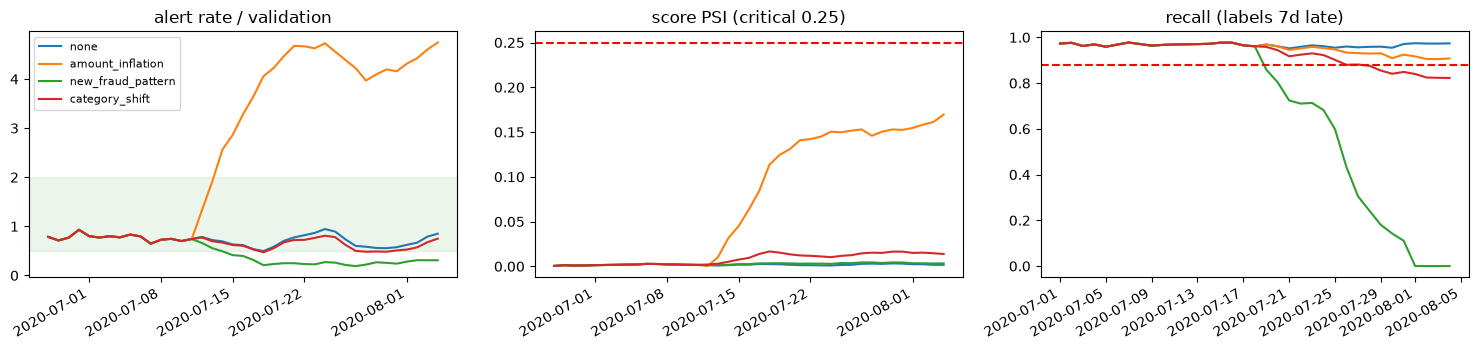

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for s, (daily, _, _) in runs.items():
    d = pd.to_datetime(daily['date'])
    axes[0].plot(d, daily['alert_rate'] / model.reference['alert_rate'], label=s)
    axes[1].plot(d, daily['psi_score'], label=s)
    axes[2].plot(d, daily['recall'], label=s)
axes[0].axhspan(0.5, 2.0, color='green', alpha=0.08); axes[0].set_title('alert rate / validation')
axes[1].axhline(0.25, ls='--', c='r'); axes[1].set_title('score PSI (critical 0.25)')
axes[2].axhline(model.reference['recall'] - 0.10, ls='--', c='r'); axes[2].set_title('recall (labels 7d late)')
axes[0].legend(fontsize=8); fig.autofmt_xdate(); plt.tight_layout()

**What it shows.** In `new_fraud_pattern` the alert rate falls below 0.5x of validation at day 23 while input PSI stays quiet: the model stops seeing the fraud. Recall (needs labels) only crosses its floor at day 28 (0.86 vs 0.88). The alert rate is not specific: `none` also crosses its floor, at day 27, so on its own it gives a 4-day head start at best.

**Decision.** Concept drift is detectable from the score distribution before any label exists, so an alert-rate drop with stable inputs is the signal to pull labeled cases, not to wait.